In [2]:
# importation des packages
import pandas as pd
import numpy as np
import plotly.express as px

## Lecture des donnees

In [3]:
df = pd.read_csv("wheat_seeds_dataset.csv")
df.head()

,area A,perimeter,compactness,length of kernel,width of kernel,asymmetry coefficient,length of kernel groove
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175


In [4]:
# Dimension des données
df.shape

(199, 7)

In [5]:
# Infos des données
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 199 entries, 0 to 198
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   area A                   199 non-null    float64
 1   perimeter                199 non-null    float64
 2   compactness              199 non-null    float64
 3   length of kernel         199 non-null    float64
 4   width of kernel          199 non-null    float64
 5   asymmetry coefficient    199 non-null    float64
 6   length of kernel groove  199 non-null    float64
dtypes: float64(7)
memory usage: 11.0 KB


In [6]:
# Décrire les données
df.describe()

,area A,perimeter,compactness,length of kernel,width of kernel,asymmetry coefficient,length of kernel groove
count,199.000000,199.000000,199.000000,199.000000,199.000000,199.000000,199.000000
mean,14.918744,14.595829,0.870811,5.643151,3.265533,3.699217,5.420653
std,2.919976,1.310445,0.023320,0.443593,0.378322,1.471102,0.492718
min,10.590000,12.410000,0.808100,4.899000,2.630000,0.765100,4.519000
25%,12.330000,13.470000,0.857100,5.267000,2.954500,2.570000,5.046000
50%,14.430000,14.370000,0.873400,5.541000,3.245000,3.631000,5.228000
75%,17.455000,15.805000,0.886800,6.002000,3.564500,4.799000,5.879000
max,21.180000,17.250000,0.918300,6.675000,4.033000,8.315000,6.550000


In [7]:
# Renommer les index
for i in range(len(df)):
  df.rename(index = {
      i:"Graine" + str(i+1)
  }, inplace = True)
# df.index = ['Graine' + str(i +1) for i in range(len(df))]
df.head()

,area A,perimeter,compactness,length of kernel,width of kernel,asymmetry coefficient,length of kernel groove
Graine1,15.26,14.84,0.8710,5.763,3.312,2.221,5.220
Graine2,14.88,14.57,0.8811,5.554,3.333,1.018,4.956
Graine3,14.29,14.09,0.9050,5.291,3.337,2.699,4.825
Graine4,13.84,13.94,0.8955,5.324,3.379,2.259,4.805
Graine5,16.14,14.99,0.9034,5.658,3.562,1.355,5.175


In [8]:
# Matrice des données
x = df.values
x[:5]

array([[15.26  , 14.84  ,  0.871 ,  5.763 ,  3.312 ,  2.221 ,  5.22  ],
       [14.88  , 14.57  ,  0.8811,  5.554 ,  3.333 ,  1.018 ,  4.956 ],
       [14.29  , 14.09  ,  0.905 ,  5.291 ,  3.337 ,  2.699 ,  4.825 ],
       [13.84  , 13.94  ,  0.8955,  5.324 ,  3.379 ,  2.259 ,  4.805 ],
       [16.14  , 14.99  ,  0.9034,  5.658 ,  3.562 ,  1.355 ,  5.175 ]])

In [9]:
# Importer normalize
from sklearn.preprocessing import normalize
# Normaliser x
x = normalize(x)
x[:5]

array([[0.66271789, 0.64447795, 0.03782617, 0.25027806, 0.14383497,
        0.09645455, 0.22669642],
       [0.66410726, 0.65027169, 0.03932425, 0.24787982, 0.14875467,
        0.04543422, 0.22119056],
       [0.65688362, 0.64769001, 0.0416011 , 0.24321702, 0.15339543,
        0.1240678 , 0.2217959 ],
       [0.64909686, 0.65378687, 0.04199901, 0.24969593, 0.15847531,
        0.10594724, 0.2253548 ],
       [0.68244585, 0.63382053, 0.03819836, 0.23923659, 0.15061166,
        0.05729332, 0.21881396]])

## Appliquer une ACP

In [10]:
# Importer PCA
from sklearn.decomposition import PCA
#Instantier le modèle PCA avec n_components = 2
pca = PCA(n_components=2)
# Matrice des 2 composantes
features_pca = pca.fit_transform(x)
# Dataframe
df_pca = pd.DataFrame(features_pca, columns = ['PC1', 'PC2'])

In [11]:
# Part de variance des 2 composantes
round(sum(pca.explained_variance_ratio_*100),2)

np.float64(98.55)

## Kmeans

In [12]:
# Importer KMeans
from sklearn.cluster import KMeans

## La méthode elbow(coude)

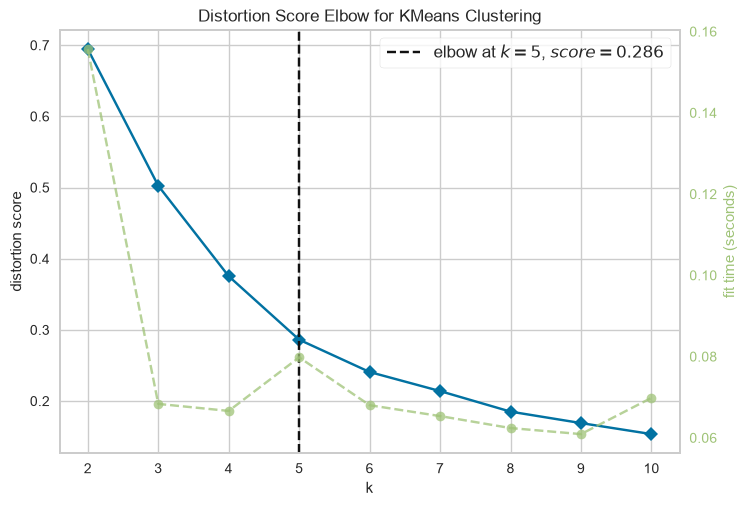

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [13]:
# importer KELbowVisualizer
from yellowbrick.cluster import KElbowVisualizer
# Instantier le modèle kmeans
kmeans_model = KMeans(init = 'random', max_iter=500)
# Instantier KELbowVisualizer
Elbow_M = KElbowVisualizer(kmeans_model, k=10)
# Entrainement
Elbow_M.fit(x)
# Visualiser l'elbow
Elbow_M.show()

## Appliquer Kmeans en utilisant le k optimal

In [14]:
# Initier le modèle
kmeans_model = KMeans(n_clusters = 5, init = 'random', max_iter = 500)
# Entrainer le modèle
kmeans_model.fit(x)

KMeans(init='random', max_iter=500, n_clusters=5)

## Prédiction la partition

In [15]:
# Prediction de la partition(l'ensemble des classes) de X
kmeans_partition = kmeans_model.predict(x)
# Afficher la partition
kmeans_partition

array([0, 0, 0, 0, 1, 0, 3, 1, 1, 3, 0, 2, 0, 0, 3, 2, 1, 0, 2, 0, 0, 1,
       0, 0, 1, 2, 0, 0, 2, 0, 3, 2, 0, 0, 0, 1, 0, 4, 0, 0, 0, 3, 0, 0,
       0, 0, 0, 0, 3, 3, 2, 0, 0, 0, 0, 0, 0, 0, 0, 2, 2, 0, 0, 0, 0, 2,
       3, 3, 3, 1, 3, 3, 3, 3, 3, 1, 3, 3, 3, 1, 1, 1, 1, 1, 3, 3, 1, 1,
       1, 3, 3, 3, 1, 1, 1, 1, 3, 1, 3, 1, 1, 1, 3, 1, 1, 1, 1, 1, 3, 3,
       1, 3, 1, 1, 1, 3, 3, 3, 1, 3, 3, 3, 1, 1, 3, 1, 1, 3, 3, 3, 3, 0,
       0, 3, 4, 4, 4, 4, 2, 4, 0, 2, 2, 4, 4, 4, 2, 2, 2, 4, 2, 2, 2, 4,
       2, 2, 4, 2, 4, 0, 2, 2, 2, 4, 4, 4, 4, 4, 4, 4, 0, 4, 2, 2, 4, 4,
       2, 4, 2, 4, 4, 4, 2, 2, 4, 2, 2, 4, 2, 2, 0, 4, 2, 2, 2, 2, 4, 2,
       4], dtype=int32)

In [16]:
# Nombre d'observations dans chaque classe
val = pd.Series(kmeans_partition).value_counts()
val

0    47
3    41
2    40
1    39
4    32
Name: count, dtype: int64

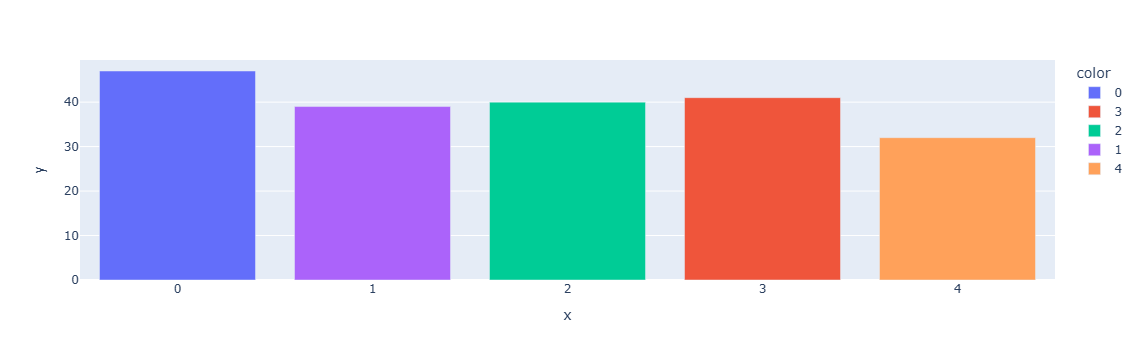

In [17]:
# Diagramme en barre du nombre d'observations dans chaque
import plotly.express as px
fig = px.bar(x = val.index, y = val.values ,color = val.index.astype(str))
fig.show()

## Visualiser les classes prédictes par Kmeans

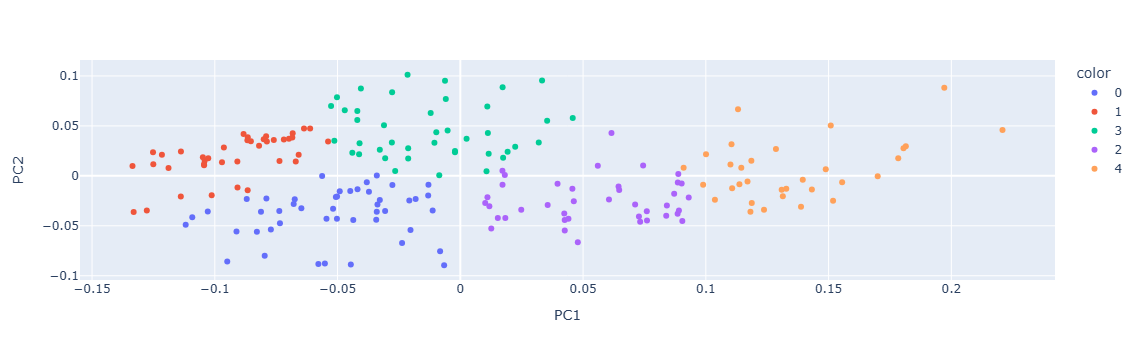

In [18]:
# Visualiser les classes suivant les deux composantes en utilisant plotly.express
fig = px.scatter(df_pca, x = 'PC1', y = 'PC2', color = kmeans_partition.astype(str))
fig.show()

## Indice de silhouette value de la partition du Kmeans

In [19]:
# Importer silhouette score
from sklearn.metrics import silhouette_score
# Indice de Silhouette value
sil_kmeans = silhouette_score(x, kmeans_partition)
print(f"Silhouette score : {sil_kmeans }")

Silhouette score : 0.37426146495332396


## CAH

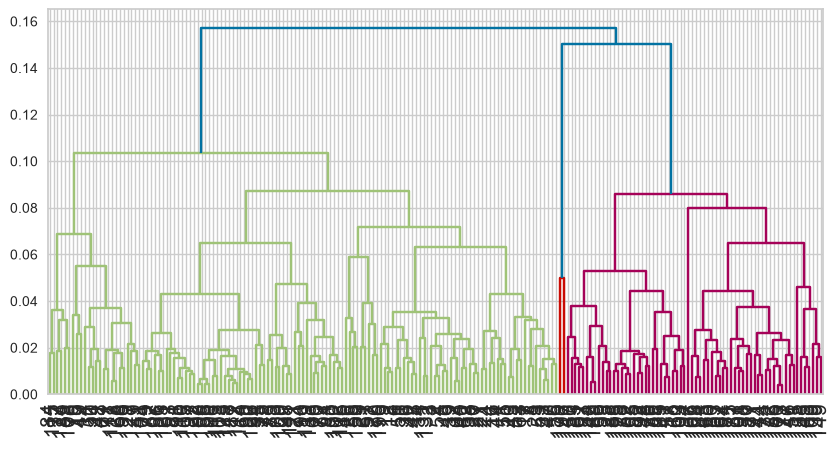

In [24]:
# Importer linkage et dendrogram
from scipy.cluster.hierarchy import  linkage, dendrogram
# Visualiser le dendrograme
import matplotlib.pyplot as plt
Z = linkage(x, 'average')# matrice des liaisons
plt.figure(figsize=(10, 5))
dendro = dendrogram(Z, leaf_font_size=15, orientation = 'top')

In [25]:
from sklearn.cluster import AgglomerativeClustering
# Initier AgglomerativeClustering
cah_model = AgglomerativeClustering(n_clusters =3, linkage = 'average')
# Entrainer le modèle
cah_model.fit(x)

AgglomerativeClustering(linkage='average', n_clusters=3)

In [26]:
# Prédire la partition des données
cah_partition = cah_model.fit_predict(x)
# Afficher la partition
cah_partition[:100]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0,
       0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [27]:
# Nombre d'observations dans chaque classe
val  = pd.Series(cah_partition).value_counts()
val

0    131
1     66
2      2
Name: count, dtype: int64

In [28]:
# Function de visualisation du diagramme en barre des nombres d'observations.
def bar_plot(val):
  fig = px.bar(x = val.index.astype(str), y = val.values, color = val.index.astype(str), text_auto = True)
  fig.show()

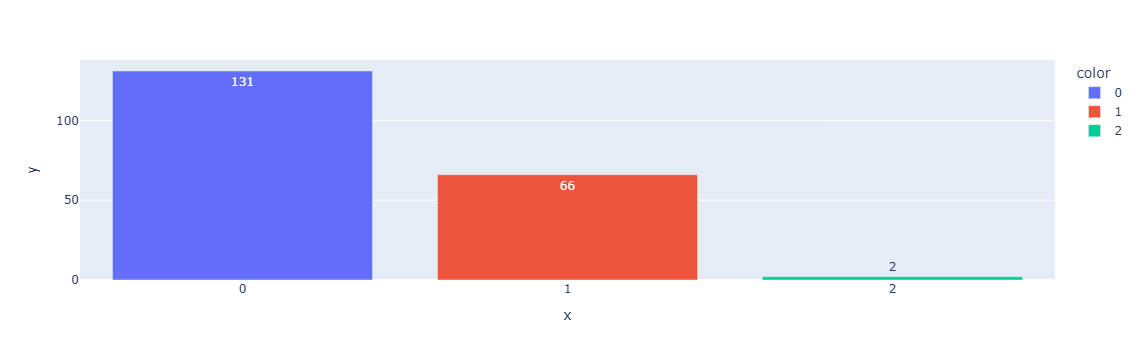

In [29]:
# Diagramme en barre des nombres d'observations
bar_plot(val)

In [30]:
# Function de visualisuation des classes
def scatter_plot(data_pca,Pred):
  fig = px.scatter(df_pca, x='PC1', y='PC2', color=Pred.astype(str))
  fig.show()

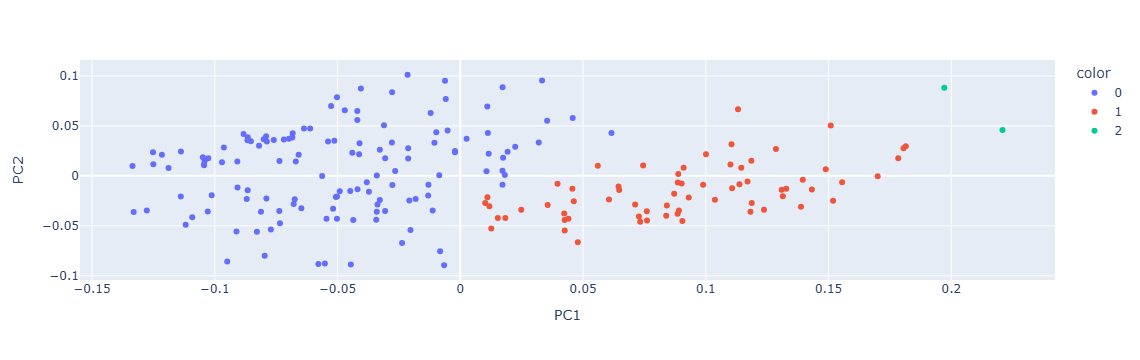

In [31]:
# Visualiser les classes
scatter_plot(df_pca, cah_partition)

In [32]:
# Silhouette score
sil_cah = silhouette_score(x, cah_partition)
print(f"La silhouette score :{sil_cah}")

La silhouette score :0.43673261131585867


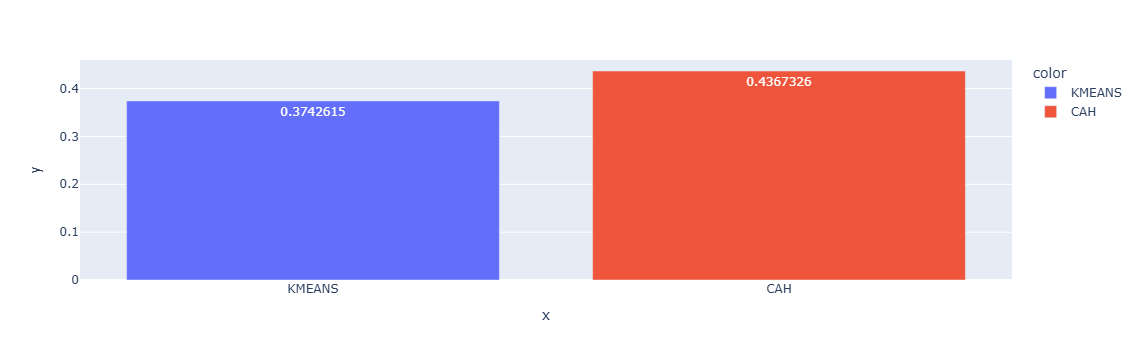

In [33]:
# Diagrammes en barre des silhouettes
Model_Names = ['KMEANS', 'CAH']
sil = [sil_kmeans, sil_cah]
fig = px.bar(x= Model_Names, y = sil, color = Model_Names, text_auto = True)
fig.show()

In [37]:
# Les graines de chaque classes
cluster_names = []
for i in range(2):
  cluster_names.append(list(df.index[cah_partition == i]))

In [40]:
 #Afficher les graines de la classe 0
print(cluster_names[0])

['Graine1', 'Graine2', 'Graine3', 'Graine4', 'Graine5', 'Graine6', 'Graine7', 'Graine8', 'Graine9', 'Graine10', 'Graine11', 'Graine12', 'Graine13', 'Graine14', 'Graine15', 'Graine16', 'Graine17', 'Graine18', 'Graine20', 'Graine21', 'Graine22', 'Graine23', 'Graine24', 'Graine25', 'Graine27', 'Graine28', 'Graine30', 'Graine31', 'Graine32', 'Graine33', 'Graine34', 'Graine35', 'Graine36', 'Graine37', 'Graine39', 'Graine40', 'Graine41', 'Graine42', 'Graine43', 'Graine44', 'Graine45', 'Graine46', 'Graine47', 'Graine48', 'Graine49', 'Graine50', 'Graine51', 'Graine52', 'Graine53', 'Graine54', 'Graine55', 'Graine56', 'Graine57', 'Graine58', 'Graine59', 'Graine62', 'Graine63', 'Graine64', 'Graine65', 'Graine67', 'Graine68', 'Graine69', 'Graine70', 'Graine71', 'Graine72', 'Graine73', 'Graine74', 'Graine75', 'Graine76', 'Graine77', 'Graine78', 'Graine79', 'Graine80', 'Graine81', 'Graine82', 'Graine83', 'Graine84', 'Graine85', 'Graine86', 'Graine87', 'Graine88', 'Graine89', 'Graine90', 'Graine91', 

In [52]:
# Importer Gradio
import tqdm as notebook_tqdm
import gradio as gr

In [48]:
import numpy as np
import tqdm as notebook_tqdm
import gradio as gr
from scipy.spatial.distance import cdist

# Calculer les centroïdes
classes = np.unique(cah_partition)
centroides = np.array([x[cah_partition == c].mean(axis=0) for c in classes])

# Prédiction : la classe du centroïde le plus proche
def predire_classe_km(nouveau_grain):
    grain = normalize(np.array(nouveau_grain, dtype=float).reshape(1, -1))
    distances = cdist(grain, centroides)
    return classes[distances.argmin()]

In [49]:
# Test rapide
print("Classe prédite :", predire_classe_km(df.iloc[0].values))
print("Classe réelle de cah :", cah_partition[3])

Classe prédite : 0
Classe réelle de cah : 0


In [50]:
# Profil moyen de chaque classe (sans les anomalies)
profil = df.groupby(cah_partition).mean().round(2)
profil

,area A,perimeter,compactness,length of kernel,width of kernel,asymmetry coefficient,length of kernel groove
0,16.44,15.27,0.88,5.85,3.47,3.10,5.58
1,11.99,13.31,0.85,5.25,2.86,4.75,5.11
2,12.22,13.24,0.87,5.16,3.03,7.92,5.01


In [63]:
# Noms des classes
noms_classes = {
    0: "Kama",
    1: "Rosa",
    2: "Canadian"
}

In [64]:
def affecter_grain(*valeurs):
    if any(v is None or v < 0 for v in valeurs):
        raise gr.Error("Aucun champ ne peut être vide ou négatif.")
    ble = normalize(np.array(valeurs, dtype=float).reshape(1, -1))
    g = int(classes[cdist(ble, centroides).argmin()])
    return f"Groupe {g} : {noms_classes[g]}"

In [65]:
import gradio as gr

# Un champ par variable, prérempli avec la valeur médiane
champs = [gr.Number(label=col, value=float(df[col].median()))
          for col in df.columns]
exemples = df.head(3).values.tolist()
interface = gr.Interface(
    fn=affecter_grain,
    inputs=champs,
    outputs=gr.Textbox(label="Résultat"),
    title="Segmentation des verres - modèle CAH",
    description="Saisissez la composition d'un verre pour connaître son groupe.",
    examples=exemples,
)

In [66]:
# Lancer l'application
interface.launch(share=True)

* Running on local URL:  http://127.0.0.1:7866

Could not create share link. Please check your internet connection or our status page: https://status.gradio.app.


In [69]:
import joblib
joblib.dump({
    "methode": "CAH",
    "cah_model": cah_model,
    "centroides": centroides,
    "classes": np.array([0, 1, 2]),
    "colonnes": list(df.columns),
    "descriptions": noms_classes,
    "normalisation": "normalize",
    "medianes": df.median().to_dict()
}, "modeles/grain.pkl")                         # un nom par notebook

['modeles/grain.pkl']